In [ ]:
# ERDDAP Multi-Year ADCP (contour)



In [1]:
import xarray as xa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
url = 'http://ecofoci-field.pmel.noaa.gov:8081/erddap/griddap/ADCP_Full_upp3_record'

In [3]:
xdf = xa.load_dataset(url)

In [4]:
#prefilter any known issues

xdf = xdf.where(xdf.depth>12)

In [5]:
udata = xdf.u_comp_current
vdata = xdf.v_comp_current

In [6]:
#rotate currents
rot = 45

angle_offset_rad = np.deg2rad(rot)
udatap = udata*np.cos(angle_offset_rad) + vdata*np.sin(angle_offset_rad)
vdatap = -1*udata*np.sin(angle_offset_rad) + vdata*np.cos(angle_offset_rad)

magnitude = np.sqrt(udatap**2 + vdatap**2)



In [15]:
vdata

<xarray.DataArray 'v_comp_current' (time: 26113, depth: 63)> Size: 7MB
array([[      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       ...,
       [      nan,       nan,       nan, ..., 28.713768,       nan,
              nan],
       [      nan,       nan,       nan, ..., 20.519299,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan]], shape=(26113, 63), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 209kB 2022-05-05 ... 2025-04-27
  * depth    (depth) float64 504B 0.0 1.0 2.0 3.0 4.0 ... 59.0 60.0 61.0 62.0
Attributes:
    ioos_category:  Currents
    long_name:      V Comp Current
    units:          cm/s

(np.float64(19570.0), np.float64(19997.0))

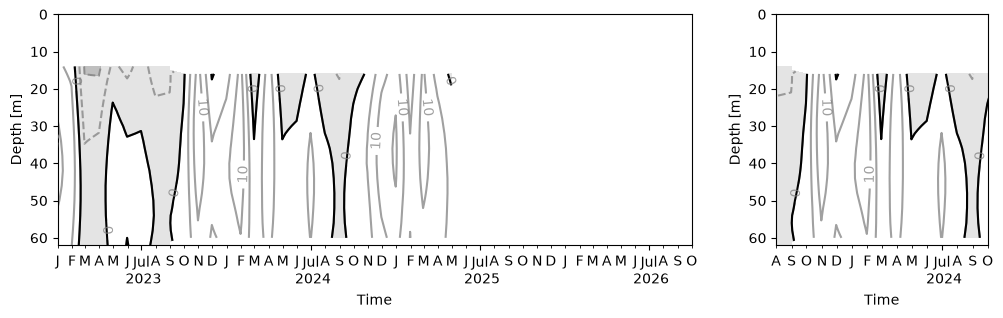

In [12]:
import datetime
from matplotlib.dates import YearLocator, MonthLocator, DateFormatter
from matplotlib.ticker import FuncFormatter

month_fmt = DateFormatter('%b')
def m_fmt(x, pos=None):
    return month_fmt(x)[0]
    
fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(12, 3),width_ratios=[3,1])
CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[0],
              yincrease=False,
              levels=range(-25,25,5),
              colors='grey', alpha=0.75)
)
ax[0].clabel(CS, inline=True, levels=range(-20,20,10), fontsize=10)

CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contourf(ax=ax[0],
              yincrease=False,
              levels=range(-10,1,10),
              cmap='Greys_r',add_colorbar=False,alpha=.25)
)

CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[0],
              yincrease=False,
              levels=[0],
              colors='black')
)



ax[0].xaxis.set_major_locator(YearLocator(month=7))
ax[0].xaxis.set_minor_locator(MonthLocator(bymonthday=1))
ax[0].xaxis.set_minor_formatter(DateFormatter('%b'))
ax[0].xaxis.set_major_formatter(DateFormatter('%b\n %Y'))
ax[0].xaxis.set_tick_params(which='major', pad=3)
ax[0].xaxis.set_tick_params(which='minor', pad=5)
ax[0].xaxis.set_minor_formatter(FuncFormatter(m_fmt))

ax[0].set_xlim([datetime.date(2023,1,1),datetime.date(2026,10,1)])

CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[1],
              yincrease=False,
              levels=range(-25,25,5),
              colors='grey', alpha=0.75)
)
ax[1].clabel(CS, inline=True, levels=range(-20,20,10), fontsize=10)

CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[1],
              yincrease=False,
              levels=[0],
              colors='black')
)

CS = (
 vdata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contourf(ax=ax[1],
              yincrease=False,
              levels=range(-10,1,10),
              cmap='Greys_r',add_colorbar=False,alpha=.25)
)

ax[1].xaxis.set_major_locator(YearLocator(month=7))
ax[1].xaxis.set_minor_locator(MonthLocator(bymonthday=1))
ax[1].xaxis.set_minor_formatter(DateFormatter('%b'))
ax[1].xaxis.set_major_formatter(DateFormatter('%b\n %Y'))
ax[1].xaxis.set_tick_params(which='major', pad=3)
ax[1].xaxis.set_tick_params(which='minor', pad=5)
ax[1].xaxis.set_minor_formatter(FuncFormatter(m_fmt))

ax[1].set_xlim([datetime.date(2023,8,1),datetime.date(2024,10,1)])

(np.float64(19570.0), np.float64(19997.0))

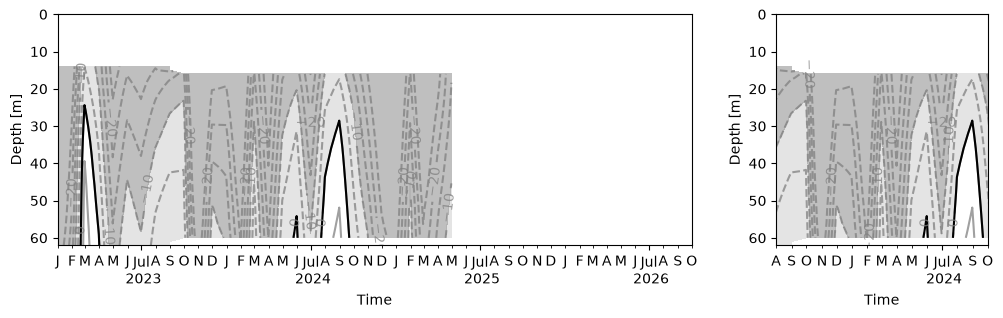

In [14]:
import datetime
from matplotlib.dates import YearLocator, MonthLocator, DateFormatter
from matplotlib.ticker import FuncFormatter

month_fmt = DateFormatter('%b')
def m_fmt(x, pos=None):
    return month_fmt(x)[0]
    
fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(12, 3),width_ratios=[3,1])
CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[0],
              yincrease=False,
              levels=range(-25,25,5),
              colors='grey', alpha=0.75)
)
ax[0].clabel(CS, inline=True, levels=range(-20,20,10), fontsize=10)

CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contourf(ax=ax[0],
              yincrease=False,
              levels=range(-10,1,10),
              cmap='Greys_r',add_colorbar=False,alpha=.25)
)

CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[0],
              yincrease=False,
              levels=[0],
              colors='black')
)



ax[0].xaxis.set_major_locator(YearLocator(month=7))
ax[0].xaxis.set_minor_locator(MonthLocator(bymonthday=1))
ax[0].xaxis.set_minor_formatter(DateFormatter('%b'))
ax[0].xaxis.set_major_formatter(DateFormatter('%b\n %Y'))
ax[0].xaxis.set_tick_params(which='major', pad=3)
ax[0].xaxis.set_tick_params(which='minor', pad=5)
ax[0].xaxis.set_minor_formatter(FuncFormatter(m_fmt))

ax[0].set_xlim([datetime.date(2023,1,1),datetime.date(2026,10,1)])

CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[1],
              yincrease=False,
              levels=range(-25,25,5),
              colors='grey', alpha=0.75)
)
ax[1].clabel(CS, inline=True, levels=range(-20,20,10), fontsize=10)

CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contour(ax=ax[1],
              yincrease=False,
              levels=[0],
              colors='black')
)

CS = (
 udata.interpolate_na(dim='depth').
 resample(time='ME').
 mean().
 T.
 plot.contourf(ax=ax[1],
              yincrease=False,
              levels=range(-10,1,10),
              cmap='Greys_r',add_colorbar=False,alpha=.25)
)

ax[1].xaxis.set_major_locator(YearLocator(month=7))
ax[1].xaxis.set_minor_locator(MonthLocator(bymonthday=1))
ax[1].xaxis.set_minor_formatter(DateFormatter('%b'))
ax[1].xaxis.set_major_formatter(DateFormatter('%b\n %Y'))
ax[1].xaxis.set_tick_params(which='major', pad=3)
ax[1].xaxis.set_tick_params(which='minor', pad=5)
ax[1].xaxis.set_minor_formatter(FuncFormatter(m_fmt))

ax[1].set_xlim([datetime.date(2023,8,1),datetime.date(2024,10,1)])